# Connection plasticity: pair STDP

A `connect` call can carry a plasticity rule. The rule then changes the weight of
every row of that call while the model runs; `ConnectionView.rule_state("w")`
reads the current weight. This tutorial uses the built-in rule,
`braincell.plasticity.PairSTDP`, all-to-all pair spike-timing-dependent
plasticity with additive updates.

Read [Connection](connection.ipynb) first: a rule is declared on the same
`connect` call that routes the events.

In [1]:
import os

os.environ.setdefault("JAX_PLATFORMS", "cpu")

import brainstate
import brainunit as u
import matplotlib.pyplot as plt
import numpy as np

import braincell
from braincell import mech

brainstate.environ.set(precision=64)

## 1. Declaring a rule

`mech.ConnectionRule` names a rule and its parameters, as `mech.Synapse` names a
synapse model. Every row of a pair rule keeps a presynaptic trace $x$ and a
postsynaptic trace $y$, which decay with $\tau_+$ and $\tau_-$. At an event
boundary where a row has $n_\mathrm{pre}$ arrivals and its target member
$n_\mathrm{post}$ spikes, the rule reads the state just before the boundary:

$$w \leftarrow w + A_+\, x\, n_\mathrm{post} - A_-\, y\, n_\mathrm{pre},\qquad
x \leftarrow x + n_\mathrm{pre},\qquad y \leftarrow y + n_\mathrm{post}.$$

So a pre event $\Delta t$ before a post event adds $A_+ e^{-\Delta t/\tau_+}$, a
post event $\Delta t$ before a pre event subtracts $A_- e^{-\Delta t/\tau_-}$,
and a pre and a post event on the same boundary do not pair.

The `post` events default to the target Cell's own spikes. Here a scheduled
source stands in for them as a teaching signal, so that the point neuron needs
no channels: a pre event at 0 ms and a post event at 10 ms.

In [2]:
cell = braincell.Cell.point(1, V_init=-65.0 * u.mV)
cell.place(mech.Synapse("ExpSyn", name="s", tau=2.0 * u.ms, e=0.0 * u.mV))

stdp = mech.ConnectionRule(
    "PairSTDP",
    A_plus=0.01 * u.uS,
    A_minus=0.0105 * u.uS,
    tau_plus=20.0 * u.ms,
    tau_minus=20.0 * u.ms,
    signals={"post": braincell.EventSequence.from_times(([10.0] * u.ms,))},
)
braincell.connect(
    "c",
    source=braincell.EventSequence.from_times(([0.0] * u.ms,)),
    synapse=cell.synapses["s"],
    weight=0.05 * u.uS,
    plasticity=stdp,
)
cell.run(dt=0.1 * u.ms, duration=12.0 * u.ms)

dw = cell.connections["c"].rule_state("w") - 0.05 * u.uS
print("simulated:", dw)
print("reference:", 0.01 * np.exp(-10.0 / 20.0) * u.uS)

simulated: [0.00606531] uS
reference: 0.00606531 uS


`rule_state` also reads the traces, `"x_pre"` and `"y_post"`. The event a row
delivers at a boundary carries the weight *before* that boundary's update, so
the synapse here received 0.05 uS at 0 ms.

In [3]:
print("x_pre :", cell.connections["c"].rule_state("x_pre"))
print("y_post:", cell.connections["c"].rule_state("y_post"))

x_pre : [0.54881164]
y_post: [0.90483742]


## 2. The STDP window in one run

Each row has its own state, so one Cell population can measure the whole window
at once: member $i$ gets a pre event at 60 ms and a post event at
$60 + \Delta t_i$ ms. The rule's parameters may also be one value per row; here
they are shared.

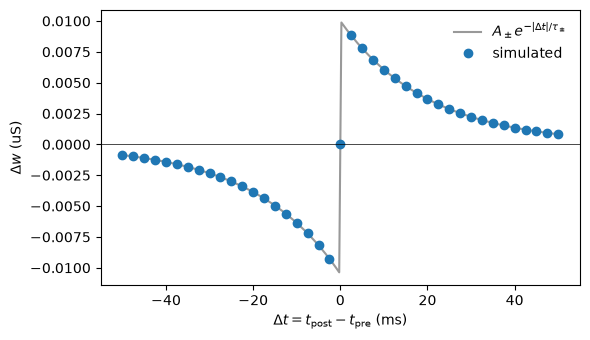

In [4]:
lags = np.arange(-50.0, 50.1, 2.5)
n = lags.size

window_cell = braincell.Cell.point(n, V_init=-65.0 * u.mV)
window_cell.place(mech.Synapse("ExpSyn", name="s", tau=2.0 * u.ms, e=0.0 * u.mV))
pre = braincell.EventSequence.from_times(tuple([60.0] * u.ms for _ in range(n)))
post = braincell.EventSequence.from_times(tuple([60.0 + lag] * u.ms for lag in lags))
rule = mech.ConnectionRule(
    "PairSTDP",
    A_plus=0.01 * u.uS,
    A_minus=0.0105 * u.uS,
    tau_plus=20.0 * u.ms,
    tau_minus=20.0 * u.ms,
    signals={"post": post},
)
braincell.connect("c", source=pre, synapse=window_cell.synapses["s"], weight=0.05 * u.uS, plasticity=rule)
window_cell.run(dt=0.1 * u.ms, duration=120.0 * u.ms)
dw = (window_cell.connections["c"].rule_state("w") - 0.05 * u.uS).to_decimal(u.uS)

dense = np.linspace(-50.0, 50.0, 401)
reference = np.where(dense > 0, 0.01 * np.exp(-dense / 20.0), -0.0105 * np.exp(dense / 20.0))
reference[dense == 0] = 0.0

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(dense, reference, color="0.6", label=r"$A_\pm e^{-|\Delta t|/\tau_\pm}$")
ax.plot(lags, dw, "o", label="simulated")
ax.axhline(0.0, color="k", lw=0.5)
ax.set_xlabel(r"$\Delta t = t_\mathrm{post} - t_\mathrm{pre}$ (ms)")
ax.set_ylabel(r"$\Delta w$ (uS)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 3. Weight trajectories and bounds

Thirty rows share one synapse and a regular 10 Hz teaching signal. Ten rows fire
5–10 ms before each post event, ten fire 5–10 ms after it, and ten fire at
random times. `w_min` and `w_max` clip the weight after every update.

`rule_state` reads the weight between runs; consecutive `run` calls continue the
same simulation, so running in 50 ms segments samples the trajectory.

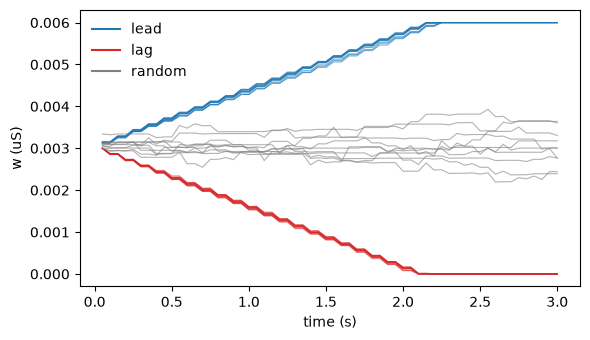

In [5]:
rng = np.random.default_rng(0)
duration = 3000.0
post_times = np.arange(50.0, duration, 100.0)
groups = {"lead": range(0, 10), "lag": range(10, 20), "random": range(20, 30)}
pre_times = []
for i in range(30):
    if i in groups["lead"]:
        t = post_times - 5.0 - rng.uniform(0.0, 5.0, post_times.size)
    elif i in groups["lag"]:
        t = post_times + 5.0 + rng.uniform(0.0, 5.0, post_times.size)
    else:
        t = np.sort(rng.uniform(0.0, duration, post_times.size))
    pre_times.append(np.round(t, 1) * u.ms)

traj_cell = braincell.Cell.point(1, V_init=-65.0 * u.mV)
traj_cell.place(mech.Synapse("ExpSyn", name="s", tau=2.0 * u.ms, e=0.0 * u.mV))
rule = mech.ConnectionRule(
    "PairSTDP",
    A_plus=0.0002 * u.uS,
    A_minus=0.00021 * u.uS,
    tau_plus=20.0 * u.ms,
    tau_minus=20.0 * u.ms,
    w_min=0.0 * u.uS,
    w_max=0.006 * u.uS,
    signals={"post": braincell.EventSequence.from_times((post_times * u.ms,))},
)
braincell.connect(
    "inputs",
    source=braincell.EventSequence.from_times(tuple(pre_times)),
    synapse=traj_cell.synapses["s"],
    weight=0.003 * u.uS,
    plasticity=rule,
)

segment = 50.0
times, weights = [], []
for k in range(int(duration // segment)):
    traj_cell.run(dt=0.1 * u.ms, duration=segment * u.ms)
    times.append((k + 1) * segment)
    weights.append(traj_cell.connections["inputs"].rule_state("w").to_decimal(u.uS))
weights = np.stack(weights)

fig, ax = plt.subplots(figsize=(6, 3.5))
for (name, rows), color in zip(groups.items(), ("C0", "C3", "0.5")):
    ax.plot(np.asarray(times) / 1000.0, weights[:, list(rows)], color=color, lw=0.8, alpha=0.6)
    ax.plot([], [], color=color, label=name)
ax.set_xlabel("time (s)")
ax.set_ylabel("w (uS)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

`reset_state()` starts the rule again from the rows' weight, and
`set(weight=...)` changes both that weight and the current one. A weight outside
`[w_min, w_max]` is rejected rather than clipped.

In [6]:
traj_cell.reset_state()
print("after reset_state:", traj_cell.connections["inputs"][:3].rule_state("w"))
traj_cell.connections["inputs"][:3].set(weight=0.001 * u.uS)
print("after set        :", traj_cell.connections["inputs"][:3].rule_state("w"))
try:
    traj_cell.connections["inputs"][:3].set(weight=0.01 * u.uS)
except ValueError as error:
    print("ValueError:", error)

after reset_state: [0.003 0.003 0.003] uS
after set        : [0.001 0.001 0.001] uS
ValueError: PairSTDP weight of 3 row(s) (first: row 0, 0.01 uS) is outside w_max=Quantity(0.006, "uS"); the rule rejects a weight outside its bounds rather than clipping it.


## 4. Live sources and delays

With a live source, such as another Cell's spikes, the rule runs in a
`Network`. A row's pre time is its *arrival*, after its delay. Below, one
presynaptic neuron fires once at about 10 ms and drives three postsynaptic
members through rows with delays of 0, 2 and 5 ms. A strong fixed input makes
every member fire at about 20 ms; their own spikes are the `post` events (no
`signals=`). The longer the delay, the closer the arrival to the post spike and
the larger the potentiation.

In [7]:
def hh_point(size):
    cell = braincell.Cell.point(size, V_init=-65.0 * u.mV, V_th=-20.0 * u.mV)
    cell.paint(
        mech.Ion("SodiumFixed", E=50.0 * u.mV),
        mech.Ion("PotassiumFixed", E=-77.0 * u.mV),
        mech.Channel("Na_HH1952", g_max=120.0 * u.mS / u.cm**2),
        mech.Channel("K_HH1952", g_max=36.0 * u.mS / u.cm**2),
        mech.Channel("IL", g_max=0.3 * u.mS / u.cm**2, E=-54.4 * u.mV),
    )
    return cell


pre_cell = hh_point(1)
pre_cell.place(mech.CurrentClamp(delay=10.0 * u.ms, durations=(1.0 * u.ms,), amplitudes=(0.5 * u.nA,)))
post_cell = hh_point(3)
post_cell.place(mech.Synapse("ExpSyn", name="exc", tau=2.0 * u.ms, e=0.0 * u.mV))

net = braincell.Network("live_stdp")
pre_pop = net.add_population("pre", pre_cell)
post_pop = net.add_population("post", post_cell)
drive = net.add_population("drive", braincell.EventSequence.from_times(([20.0] * u.ms,)))
net.connect("drive", source=drive.event_outputs["event"], synapse=post_pop.synapses["exc"], weight=0.05 * u.uS)

delays = [0.0, 2.0, 5.0] * u.ms
rule = mech.ConnectionRule(
    "PairSTDP", A_plus=0.01 * u.uS, A_minus=0.0105 * u.uS, tau_plus=20.0 * u.ms, tau_minus=20.0 * u.ms
)
net.connect(
    "plastic",
    source=pre_pop.event_outputs["spike"],
    synapse=post_pop.synapses["exc"],
    weight=0.0001 * u.uS,
    delay=delays,
    plasticity=rule,
)
dt = 0.025 * u.ms
result = net.run(dt=dt, duration=40.0 * u.ms)

pre_spike = result.events["pre"]["spike"].time
post_spike = result.events["post"]["spike"].time
print("pre spike step starts at:", pre_spike)
print("post spike steps start at:", post_spike)
print("dw:", post_cell.connections["plastic"].rule_state("w") - 0.0001 * u.uS)

pre spike step starts at: [10.275] ms
post spike steps start at: [20.075 20.075 20.075] ms
dw: [0.00612626 0.00676211 0.00785645] uS


A spike detected in the step that starts at $t_m$ is an event at the boundary
$t_m + dt$; with a delay of $k \ge 1$ steps it arrives at $t_m + k\,dt$, and
with no delay at the end of the detection step. The reference below follows
these times.

In [8]:
t_pre = float(pre_spike.to_decimal(u.ms)[0])
t_post = post_spike.to_decimal(u.ms) + dt.to_decimal(u.ms)
arrival = t_pre + np.maximum(delays.to_decimal(u.ms), dt.to_decimal(u.ms))
print("reference dw (uS):", 0.01 * np.exp(-(t_post - arrival) / 20.0))

reference dw (uS): [0.00612626 0.00676211 0.00785645]


A standalone `Cell.run` delivers live events on another schedule, so it
rejects a rule on a live source and points to `Network`; scheduled sources,
as in sections 1–3, work in both.

In [9]:
lone = braincell.Cell.point(1, V_init=-65.0 * u.mV)
lone.place(mech.Synapse("ExpSyn", name="s"))
braincell.connect(
    "self", source=lone.event_outputs["spike"], synapse=lone.synapses["s"], weight=0.001 * u.uS, delay=1.0 * u.ms, plasticity=rule
)
try:
    lone.run(dt=0.1 * u.ms, duration=1.0 * u.ms)
except NotImplementedError as error:
    print("NotImplementedError:", error)

NotImplementedError: Connection 'self' has a plasticity rule on a live source, which runs only in a braincell.Network: a standalone Cell.run delivers live events on another schedule. Add the Cells to a Network and run that, or connect a scheduled source (EventSequence, NetStim).


## Notes

- One rule covers every row of its `connect` call; rows without a rule are
  unchanged. Each call with a rule has its own state.
- The rule state lives on the target Cell, in its state tree, and the dynamic
  weight starts from the rows' weight at `init_state` and `reset_state`. A
  trainable bound to the rows' weight (`trainable(weight=...)`) therefore stays
  differentiable through the rule.
- A new rule subclasses `braincell.ConnectionRule` and is registered with
  `braincell.mech.register_connection_rule`; see the API reference.